# 03b — Anomaly Detection, Semi-Synthetic Benchmark & Spatial Hotspots

**Project:** `miniproject2026` — Spatio-Temporal Satellite Water Contamination Analysis & Illegal Dumping Detection Engine  
**Stage:** Day 2 — Steps 5 & 6  
**Objectives:**
1. **Part A (Step 5):** Build a strictly causal, per-lake trailing robust Z-score anomaly detector over six water-quality indicators (`NDCI_med`, `NDTI_med`, `NDCI_p90`, `NDTI_p90`, `pred_chla_proxy`, `pred_tss_proxy`) using real Sentinel-2 observations and saved Random Forest baseline bundles (`models/baseline_chla.pkl`, `models/baseline_tss.pkl`). Save `data/processed/sentinel_anomalies.csv` and diagnostic figures.
2. **Part B (Shared Benchmark):** Lock a chronological train/test split (first 24 dates = reference, last 8 dates = held-out test per lake; 32 normal + 32 localized-plume injected = 64 cases) with transparent patch-and-tabular consistency checks, evaluate Precision / Recall / F1 / ROC-AUC, export `data/processed/anomaly_benchmark.csv` and `data/processed/anomaly_benchmark.npz`, and append benchmark metrics to `models/baseline_metrics.json`.
3. **Part C (Step 6):** Extract within-lake spatial pollution hotspots from historical Sentinel-2 patches inside valid water masks (`water_mask > 0.5`), remove tiny clusters (`< 3` px), convert north-up pixel centroids to WGS84 (`EPSG:4326`), verify 100% containment inside `data/processed/lake_boundaries/*.geojson`, export `data/processed/spatial_hotspots.json`, and generate `docs/figures/hotspots_verification.png`.

> **Scientific Scope & Limitations:** Real Sentinel-2 observations have no verified ground-truth illegal-dumping labels; statistical anomalies indicate unusual temporal shifts rather than confirmed pollution events. Semi-synthetic benchmark metrics measure sensitivity to localized physical plume injections only.

## 1. Environment Setup & Project Schema Inspection

Verify directory paths, official `SPEC.md` water body IDs (`bellandur`, `hussain_sagar`, `yamuna_okhla`, `sukhna`), saved baseline model bundles, Sentinel-2 CSV observations, NPZ patches, and GeoJSON boundaries before processing.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch as MplPatch
from matplotlib.path import Path as MplPath
from scipy import ndimage
from sklearn.metrics import (
    auc,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

# Locate repository root containing SPEC.md
CWD = Path.cwd().resolve()
ROOT = CWD if (CWD / "SPEC.md").exists() else CWD.parent
assert (ROOT / "SPEC.md").exists(), f"SPEC.md not found from {CWD}"

DATA_DIR = ROOT / "data" / "processed"
PATCH_DIR = DATA_DIR / "sentinel_patches"
BOUNDARY_DIR = DATA_DIR / "lake_boundaries"
MODELS_DIR = ROOT / "models"
FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

OFFICIAL_LAKES = ["bellandur", "hussain_sagar", "yamuna_okhla", "sukhna"]
LAKE_DISPLAY_NAMES = {
    "bellandur": "Bellandur Lake",
    "hussain_sagar": "Hussain Sagar",
    "yamuna_okhla": "Yamuna Okhla",
    "sukhna": "Sukhna Lake",
}
ANOMALY_INDICATORS = [
    "NDCI_med",
    "NDTI_med",
    "NDCI_p90",
    "NDTI_p90",
    "pred_chla_proxy",
    "pred_tss_proxy",
]
RANDOM_SEED = 42
TRAILING_WINDOW = 5
MIN_HISTORY = 3
ANOMALY_THRESHOLD = 2.0
TRAIN_REF_DATES = 24
TEST_DATES = 8

print("Repository root:", ROOT)
print("Sentinel CSV exists:", (DATA_DIR / "sentinel_timeseries.csv").exists())
print("Pre-saved sentinel_baseline_predictions.csv exists:", (DATA_DIR / "sentinel_baseline_predictions.csv").exists())

Repository root: C:\Users\somya\OneDrive\Desktop\miniproject
Sentinel CSV exists: True
Pre-saved sentinel_baseline_predictions.csv exists: False


## 2. Inspect Saved Model Bundles, Patch Schemas & Generate Baseline Proxy Predictions

In `ml/03_baseline_models.ipynb`, `EXPORT_FINAL_CSV` was `False`, so `data/processed/sentinel_baseline_predictions.csv` was not exported to disk. Rather than altering `data/processed/sentinel_timeseries.csv`, we load the exact saved model bundles (`models/baseline_chla.pkl` and `models/baseline_tss.pkl`), reconstruct their 11 required features using the exact `safe_ratio` and feature schema from `03_baseline_models.ipynb`, and verify every Sentinel-2 NPZ patch file.

In [2]:
chla_bundle = joblib.load(MODELS_DIR / "baseline_chla.pkl")
tss_bundle = joblib.load(MODELS_DIR / "baseline_tss.pkl")
with open(MODELS_DIR / "baseline_metrics.json", "r", encoding="utf-8") as f:
    baseline_metrics = json.load(f)

print("Chla model:", chla_bundle["model_name"], "| target_unit:", chla_bundle["target_unit"], "| transform:", chla_bundle["target_transform"])
print("Chla features:", chla_bundle["features"])
print("TSS model:", tss_bundle["model_name"], "| target_unit:", tss_bundle["target_unit"], "| transform:", tss_bundle["target_transform"])
print("TSS features:", tss_bundle["features"])
assert chla_bundle["features"] == tss_bundle["features"]

def safe_ratio(a: pd.Series, b: pd.Series) -> pd.Series:
    valid = a.notna() & b.notna() & np.isfinite(a) & np.isfinite(b) & (a > 0) & (b > 0)
    res = pd.Series(np.nan, index=a.index, dtype=float)
    res.loc[valid] = a.loc[valid] / b.loc[valid]
    return res

def build_model_features(frame: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame({
        "B02": frame["B02_med"].astype(float),
        "B03": frame["B03_med"].astype(float),
        "B04": frame["B04_med"].astype(float),
        "B05": frame["B05_med"].astype(float),
        "B06": frame["B06_med"].astype(float),
        "B07": frame["B07_med"].astype(float),
        "NDCI": frame["NDCI_med"].astype(float),
        "NDTI": frame["NDTI_med"].astype(float),
    }, index=frame.index)
    X["ratio_r_g"] = safe_ratio(X["B04"], X["B03"])
    X["ratio_re1_r"] = safe_ratio(X["B05"], X["B04"])
    X["ratio_g_b"] = safe_ratio(X["B03"], X["B02"])
    return X

def predict_proxies(frame: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    X = build_model_features(frame)
    pred_chla = np.maximum(0.0, np.expm1(chla_bundle["model"].predict(X[chla_bundle["features"]])))
    pred_tss = np.maximum(0.0, np.expm1(tss_bundle["model"].predict(X[tss_bundle["features"]])))
    return pred_chla, pred_tss

sentinel_df = pd.read_csv(DATA_DIR / "sentinel_timeseries.csv")
sentinel_df["date_dt"] = pd.to_datetime(sentinel_df["date"])
sentinel_df = sentinel_df.sort_values(["lake_id", "date_dt"]).reset_index(drop=True)

# Verify exact 4 lakes, 32 dates each, zero duplicates
assert sorted(sentinel_df["lake_id"].unique().tolist()) == sorted(OFFICIAL_LAKES)
for lake in OFFICIAL_LAKES:
    sub = sentinel_df[sentinel_df["lake_id"] == lake]
    assert len(sub) == 32, f"{lake} expected 32 dates, got {len(sub)}"
    assert sub["date_dt"].nunique() == 32, f"{lake} has duplicate dates"

sentinel_df["pred_chla_proxy"], sentinel_df["pred_tss_proxy"] = predict_proxies(sentinel_df)

# Inspect all 4 NPZ files
patch_meta = {}
for lake in OFFICIAL_LAKES:
    npz = np.load(PATCH_DIR / f"{lake}.npz", allow_pickle=False)
    patches = npz["patches"]
    dates = [str(d) for d in npz["dates"]]
    bounds = [float(b) for b in npz["bounds"]]
    channels = [str(c) for c in npz["channel_names"]]
    csv_dates = sentinel_df.loc[sentinel_df["lake_id"] == lake, "date"].tolist()
    assert patches.shape == (32, 9, 64, 64), f"{lake} unexpected shape {patches.shape}"
    assert dates == csv_dates, f"{lake} NPZ/CSV date mismatch"
    patch_meta[lake] = {
        "shape": patches.shape,
        "dtype": str(patches.dtype),
        "channels": channels,
        "bounds": bounds,
        "dates": dates,
        "water_px_min": int((patches[:, channels.index("water_mask")] > 0.5).sum(axis=(1, 2)).min()),
        "water_px_max": int((patches[:, channels.index("water_mask")] > 0.5).sum(axis=(1, 2)).max()),
    }
    print(f"{lake:13s} | shape={patches.shape} | channels={channels} | water_px={patch_meta[lake]['water_px_min']}..{patch_meta[lake]['water_px_max']} | bounds={bounds}")

# Check explicit missing-band compatibility: B07 vs B8A
patch_channels = patch_meta["bellandur"]["channels"]
missing_in_patch = [f for f in ["B02", "B03", "B04", "B05", "B06", "B07"] if f not in patch_channels]
print("\nCRITICAL PATCH/MODEL COMPATIBILITY CHECK:")
print("  Saved RF requires bands: ['B02', 'B03', 'B04', 'B05', 'B06', 'B07'] + ['NDCI', 'NDTI', 'ratio_r_g', 'ratio_re1_r', 'ratio_g_b']")
print("  NPZ channels present   :", patch_channels)
print("  Missing in NPZ patches :", missing_in_patch, "(B8A is present instead and is NOT substituted for B07 or B08)")

Chla model: RandomForest (n=300,max_depth=12,min_leaf=5) | target_unit: mg/m³ | transform: log1p
Chla features: ['B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'NDCI', 'NDTI', 'ratio_r_g', 'ratio_re1_r', 'ratio_g_b']
TSS model: RandomForest (n=300,max_depth=12,min_leaf=5) | target_unit: mg/L | transform: log1p
TSS features: ['B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'NDCI', 'NDTI', 'ratio_r_g', 'ratio_re1_r', 'ratio_g_b']


bellandur     | shape=(32, 9, 64, 64) | channels=['B02', 'B03', 'B04', 'B05', 'B06', 'B8A', 'NDCI', 'NDTI', 'water_mask'] | water_px=30..233 | bounds=[77.64075188919229, 12.91753137471545, 77.68732124674973, 12.948469655205798]
hussain_sagar | shape=(32, 9, 64, 64) | channels=['B02', 'B03', 'B04', 'B05', 'B06', 'B8A', 'NDCI', 'NDTI', 'water_mask'] | water_px=814..931 | bounds=[78.45247273526158, 17.405480530245864, 78.49451866190839, 17.444520475053615]
yamuna_okhla  | shape=(32, 9, 64, 64) | channels=['B02', 'B03', 'B04', 'B05', 'B06', 'B8A', 'NDCI', 'NDTI', 'water_mask'] | water_px=291..604 | bounds=[77.28921028472607, 28.539931519146663, 77.32480172034484, 28.577578168004305]
sukhna        | shape=(32, 9, 64, 64) | channels=['B02', 'B03', 'B04', 'B05', 'B06', 'B8A', 'NDCI', 'NDTI', 'water_mask'] | water_px=471..569 | bounds=[76.80057215636862, 30.730495442480752, 76.83743650062424, 30.754504786339957]

CRITICAL PATCH/MODEL COMPATIBILITY CHECK:
  Saved RF requires bands: ['B02', 'B03

## 3. Part A (Step 5) — Per-Lake Trailing Robust Z-Score Anomaly Detector

### Rolling Reference, Warm-Up & Unit-Aware Stability Floor ($\epsilon$)
For each observation at chronological index $t \in \{0, \dots, 31\}$ within each lake:
- **Strict causality:** Only strictly previous real observations in $[ \max(0, t - 5),\, t - 1 ]$ are included in the reference window (`TRAILING_WINDOW = 5`). Observation $t$ and all future observations $> t$ are excluded.
- **Warm-up rule:** During early dates, expanding historical observations are used, requiring at least `MIN_HISTORY = 3` valid prior points ($t \ge 3$). Observations $t \in \{0, 1, 2\}$ receive `NaN` anomaly scores and `is_anomaly = False`.
- **Positive robust Z-score:**
  $$z_t^{(k)} = \max\left(0,\ rac{0.6745 \left(x_t^{(k)} - 	ext{median}_{	ext{trail}}ight)}{\max\left(	ext{MAD}_{	ext{trail}},\ \epsilon_{	ext{lake}}^{(k)}ight)}ight)$$
- **Unit-aware stability floor $\epsilon_{	ext{lake}}^{(k)}$:** Computed strictly from the lake's 24-date historical reference slice ($t < 24$, zero leakage from held-out test dates $24\dots 31$):
  - Spectral indices (`NDCI_med`, `NDTI_med`, `NDCI_p90`, `NDTI_p90`, unitless in $[-1, 1]$): $\epsilon = \max(0.02,\ 0.25 	imes 	ext{MAD}_{	ext{lake,ref}})$
  - `pred_chla_proxy` ($	ext{mg/m}^3$, RF test $	ext{MAE}=6.34\ 	ext{mg/m}^3$, $	ext{RMSE}=38.52\ 	ext{mg/m}^3$): $\epsilon = \max(10.0,\ 0.25 	imes 	ext{MAD}_{	ext{lake,ref}})$
  - `pred_tss_proxy` ($	ext{mg/L}$, RF test $	ext{MAE}=13.50\ 	ext{mg/L}$, $	ext{RMSE}=61.69\ 	ext{mg/L}$): $\epsilon = \max(15.0,\ 0.25 	imes 	ext{MAD}_{	ext{lake,ref}})$
- **Composite decision rule:** `baseline_anomaly_score = max(all 6 positive Z-scores)` and `is_anomaly = baseline_anomaly_score > 2.0`.

In [3]:
def compute_lake_epsilons(ref_frame: pd.DataFrame) -> dict[str, float]:
    """Compute per-indicator stability floors strictly from reference rows (no future leakage)."""
    eps = {}
    for col in ANOMALY_INDICATORS:
        vals = ref_frame[col].to_numpy(dtype=float)
        vals = vals[np.isfinite(vals)]
        mad_ref = float(np.median(np.abs(vals - np.median(vals)))) if len(vals) > 0 else 0.0
        if col == "pred_chla_proxy":
            base_floor = 10.0  # mg/m^3, calibrated against RF Chla test MAE (6.34 mg/m^3)
        elif col == "pred_tss_proxy":
            base_floor = 15.0  # mg/L, calibrated against RF TSS test MAE (13.50 mg/L)
        else:
            base_floor = 0.02  # dimensionless normalized spectral indices [-1, 1]
        eps[col] = max(base_floor, 0.25 * mad_ref)
    return eps

def score_observation_against_history(
    obs_values: dict[str, float],
    hist_frame: pd.DataFrame,
    epsilons: dict[str, float],
    min_history: int = MIN_HISTORY,
) -> tuple[dict[str, float], float, bool, str, int]:
    """Compute positive robust Z-scores across all 6 indicators against a trailing reference slice."""
    z_pos = {}
    hist_counts = []
    for col in ANOMALY_INDICATORS:
        x_t = float(obs_values[col])
        hist_vals = hist_frame[col].to_numpy(dtype=float)
        hist_vals = hist_vals[np.isfinite(hist_vals)]
        hist_counts.append(len(hist_vals))
        if not np.isfinite(x_t) or len(hist_vals) < min_history:
            z_pos[col] = np.nan
            continue
        med_trail = float(np.median(hist_vals))
        mad_trail = float(np.median(np.abs(hist_vals - med_trail)))
        denom = max(mad_trail, epsilons[col])
        z_raw = 0.6745 * (x_t - med_trail) / denom
        z_pos[col] = max(0.0, float(z_raw))

    effective_hist = min(hist_counts) if hist_counts else 0
    valid_scores = [v for v in z_pos.values() if np.isfinite(v)]
    if effective_hist < min_history or not valid_scores:
        return z_pos, np.nan, False, "insufficient_history", effective_hist

    comp_score = float(max(valid_scores))
    flagged = bool(comp_score > ANOMALY_THRESHOLD)

    pos_sorted = sorted(
        [(k, v) for k, v in z_pos.items() if np.isfinite(v) and v > 0.0],
        key=lambda item: item[1],
        reverse=True,
    )
    above_thresh = [(k, v) for k, v in pos_sorted if v > ANOMALY_THRESHOLD]
    if above_thresh:
        drivers = ", ".join(f"{k}({v:.2f})" for k, v in above_thresh)
    elif pos_sorted:
        drivers = "; ".join(f"{k}({v:.2f})" for k, v in pos_sorted)
    else:
        drivers = "none"

    return z_pos, comp_score, flagged, drivers, effective_hist

# Compute and display epsilon floors per lake (from first 24 historical dates)
lake_epsilons = {}
eps_rows = []
for lake in OFFICIAL_LAKES:
    ref_df = sentinel_df[sentinel_df["lake_id"] == lake].iloc[:TRAIN_REF_DATES]
    lake_epsilons[lake] = compute_lake_epsilons(ref_df)
    row = {"lake_id": lake}
    row.update({k: round(v, 4) for k, v in lake_epsilons[lake].items()})
    eps_rows.append(row)
print("Per-lake historical stability floors (epsilon, first 24 dates):")
display(pd.DataFrame(eps_rows))

# Score all 128 real observations chronologically per lake
scored_parts = []
for lake in OFFICIAL_LAKES:
    g = sentinel_df[sentinel_df["lake_id"] == lake].sort_values("date_dt").reset_index(drop=True)
    eps = lake_epsilons[lake]
    records = []
    for t in range(len(g)):
        hist_slice = g.iloc[max(0, t - TRAILING_WINDOW):t]
        obs = {col: g.loc[t, col] for col in ANOMALY_INDICATORS}
        z_pos, comp_score, flagged, drivers, hist_n = score_observation_against_history(obs, hist_slice, eps)
        rec = {f"z_pos_{col}": z_pos[col] for col in ANOMALY_INDICATORS}
        rec["hist_ref_count"] = hist_n
        rec["sufficient_history"] = bool(hist_n >= MIN_HISTORY)
        rec["baseline_anomaly_score"] = comp_score
        rec["is_anomaly"] = flagged
        rec["anomaly_drivers"] = drivers
        records.append(rec)
    part = pd.concat([g.drop(columns=["date_dt"]), pd.DataFrame(records)], axis=1)
    scored_parts.append(part)

anomalies_df = pd.concat(scored_parts, ignore_index=True)
anomalies_out_path = DATA_DIR / "sentinel_anomalies.csv"
anomalies_df.to_csv(anomalies_out_path, index=False)
print(f"Saved {anomalies_out_path} with shape {anomalies_df.shape}")

# Summary statistics per lake
summary_rows = []
for lake in OFFICIAL_LAKES:
    sub = anomalies_df[anomalies_df["lake_id"] == lake]
    valid_sub = sub[sub["sufficient_history"]]
    flagged_sub = sub[sub["is_anomaly"]]
    summary_rows.append({
        "lake_id": lake,
        "n_obs": len(sub),
        "n_with_history": len(valid_sub),
        "n_flagged": len(flagged_sub),
        "anomaly_pct_valid": round(100.0 * len(flagged_sub) / max(len(valid_sub), 1), 1),
        "max_score": round(float(valid_sub["baseline_anomaly_score"].max()), 3),
        "flagged_dates": ", ".join(flagged_sub["date"].tolist()),
    })
display(pd.DataFrame(summary_rows))

print("\nDetailed Flagged Observations Across All Four Lakes:")
display(
    anomalies_df.loc[
        anomalies_df["is_anomaly"],
        ["lake_id", "date", "baseline_anomaly_score", "anomaly_drivers", "NDCI_med", "NDTI_med", "NDCI_p90", "NDTI_p90", "pred_chla_proxy", "pred_tss_proxy"]
    ].round(4)
)

Per-lake historical stability floors (epsilon, first 24 dates):


,lake_id,NDCI_med,NDTI_med,NDCI_p90,NDTI_p90,pred_chla_proxy,pred_tss_proxy
0,bellandur,0.02,0.02,0.0215,0.0288,10.9579,15.0
1,hussain_sagar,0.02,0.02,0.0200,0.0200,17.3251,15.0
2,yamuna_okhla,0.02,0.02,0.0200,0.0200,10.0000,15.0
3,sukhna,0.02,0.02,0.0200,0.0200,10.0000,15.0


Saved C:\Users\somya\OneDrive\Desktop\miniproject\data\processed\sentinel_anomalies.csv with shape (128, 49)


,lake_id,n_obs,n_with_history,n_flagged,anomaly_pct_valid,max_score,flagged_dates
0,bellandur,32,29,20,69.0,24.401,"2025-02-06, 2025-03-15, 2025-03-28, 2025-04-04..."
1,hussain_sagar,32,29,12,41.4,7.070,"2025-02-01, 2025-02-21, 2025-04-12, 2025-04-22..."
2,yamuna_okhla,32,29,17,58.6,37.644,"2024-10-05, 2025-03-19, 2025-04-03, 2025-04-18..."
3,sukhna,32,29,14,48.3,6.006,"2024-08-31, 2025-04-23, 2025-05-23, 2025-06-12..."



Detailed Flagged Observations Across All Four Lakes:


,lake_id,date,baseline_anomaly_score,anomaly_drivers,NDCI_med,NDTI_med,NDCI_p90,NDTI_p90,pred_chla_proxy,pred_tss_proxy
4,bellandur,2025-02-06,3.3444,NDCI_p90(3.34),0.0180,-0.2627,0.4151,-0.2123,32.3179,16.4594
8,bellandur,2025-03-15,2.0223,NDCI_med(2.02),0.0919,-0.2208,0.3266,-0.1594,50.6573,31.5135
9,bellandur,2025-03-28,3.4402,"NDCI_p90(3.44), NDCI_med(2.43)",0.1766,-0.2086,0.5406,-0.1429,54.4342,13.8245
10,bellandur,2025-04-04,4.5237,"pred_chla_proxy(4.52), NDCI_med(3.98), NDCI_p9...",0.2277,-0.2533,0.4622,-0.1230,117.6736,33.7603
11,bellandur,2025-04-12,5.6316,"NDTI_p90(5.63), NDTI_med(2.41)",0.0642,-0.1472,0.3895,0.0808,50.8005,39.3776
...,...,...,...,...,...,...,...,...,...,...
122,sukhna,2026-06-07,5.3754,pred_chla_proxy(5.38),0.1509,-0.0253,0.1642,-0.0048,171.8851,50.3222
123,sukhna,2026-06-17,3.3910,pred_tss_proxy(3.39),0.1464,-0.0202,0.1588,-0.0044,125.4702,115.1668
124,sukhna,2026-09-20,3.6431,"NDCI_p90(3.64), NDCI_med(3.49)",0.2499,-0.2015,0.2668,-0.1531,101.9747,19.5257
125,sukhna,2026-09-30,3.4474,"NDCI_p90(3.45), NDCI_med(3.39)",0.2515,-0.1778,0.2664,-0.1600,115.0054,18.4609


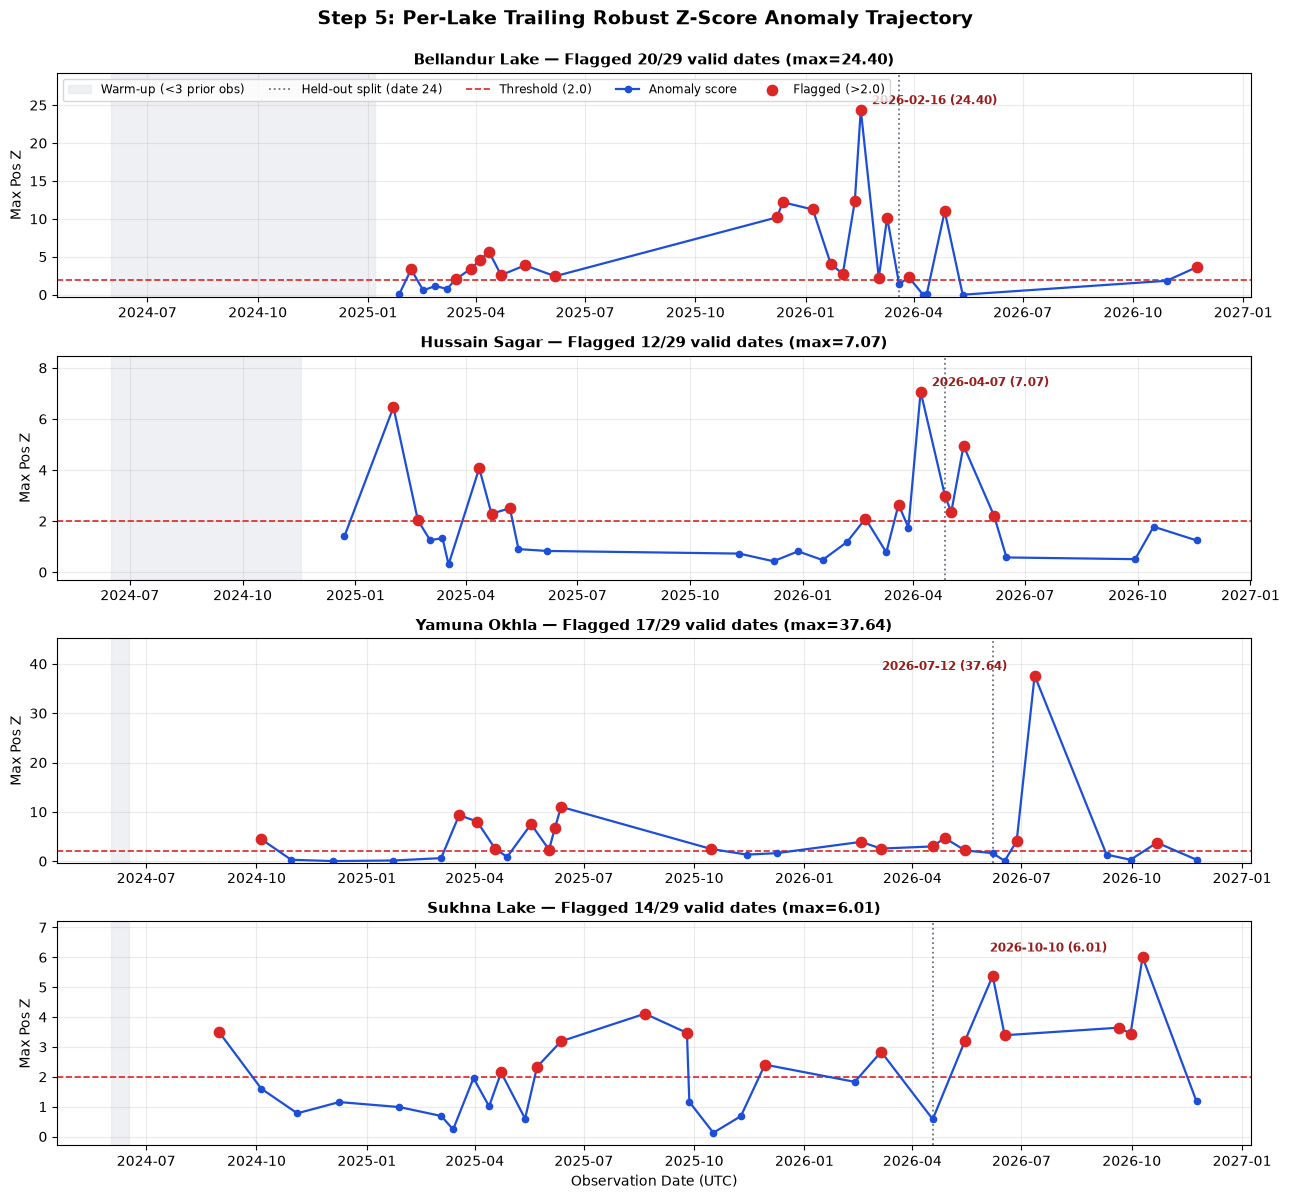

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\docs\figures\anomaly_scores_timeseries.png


In [4]:
fig, axes = plt.subplots(4, 1, figsize=(13, 12), sharex=False)
for ax, lake in zip(axes, OFFICIAL_LAKES):
    sub = anomalies_df[anomalies_df["lake_id"] == lake].copy()
    sub["dt"] = pd.to_datetime(sub["date"])
    valid = sub["sufficient_history"]
    flagged = sub["is_anomaly"]

    ax.axvspan(sub["dt"].iloc[0], sub["dt"].iloc[2], color="#e5e7eb", alpha=0.6, label="Warm-up (<3 prior obs)")
    ax.axvline(sub["dt"].iloc[TRAIN_REF_DATES], color="#6b7280", linestyle=":", linewidth=1.3, label="Held-out split (date 24)")
    ax.axhline(ANOMALY_THRESHOLD, color="#dc2626", linestyle="--", linewidth=1.2, label="Threshold (2.0)")

    ax.plot(sub.loc[valid, "dt"], sub.loc[valid, "baseline_anomaly_score"], color="#1d4ed8", linewidth=1.6, marker="o", markersize=4.5, label="Anomaly score")
    ax.scatter(sub.loc[flagged, "dt"], sub.loc[flagged, "baseline_anomaly_score"], color="#dc2626", s=55, zorder=5, label="Flagged (>2.0)")

    # Annotate top peak per lake with clean headroom
    peak_idx = sub["baseline_anomaly_score"].idxmax()
    peak_row = sub.loc[peak_idx]
    ax.set_ylim(-0.3, float(peak_row["baseline_anomaly_score"]) * 1.20)
    is_near_right = peak_row["dt"] > sub["dt"].iloc[int(0.8 * len(sub))]
    ax.annotate(
        f"{peak_row['date']} ({peak_row['baseline_anomaly_score']:.2f})",
        xy=(peak_row["dt"], peak_row["baseline_anomaly_score"]),
        xytext=(-110, 4) if is_near_right else (8, 4),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="bold",
        color="#991b1b",
    )

    ax.set_title(f"{LAKE_DISPLAY_NAMES[lake]} — Flagged {int(flagged.sum())}/{int(valid.sum())} valid dates (max={peak_row['baseline_anomaly_score']:.2f})", fontsize=11, fontweight="bold")
    ax.set_ylabel("Max Pos Z")
    ax.grid(alpha=0.25)
    if lake == OFFICIAL_LAKES[0]:
        ax.legend(loc="upper left", ncol=5, fontsize=8.5)

axes[-1].set_xlabel("Observation Date (UTC)")
fig.suptitle("Step 5: Per-Lake Trailing Robust Z-Score Anomaly Trajectory", fontsize=13.5, fontweight="bold", y=0.995)
fig.tight_layout()
anom_fig_path = FIG_DIR / "anomaly_scores_timeseries.png"
fig.savefig(anom_fig_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", anom_fig_path)

## 4. Part B — Shared Semi-Synthetic Contamination Benchmark

Because real Sentinel-2 scenes lack verified ground-truth illegal-dumping labels, we lock a reproducible 64-case held-out benchmark (`32` normal + `32` injected):
- **Chronological split:** First `24` dates per lake (`96` rows) serve strictly as historical reference (`MAD_lake_ref` and trailing 5-point reference windows); last `8` dates per lake (`32` rows) are held-out test scenes.
- **Two physical injection scenarios (alternating evenly across each lake's 8 test dates):**
  - **Scenario A (`turbidity_sediment`):** Add localized Gaussian-tapered red reflectance increase ($\Delta B04_{\max} = +0.095$, tapered $0.60	ext{–}1.0	imes$ from plume center) into $14\%	ext{–}22\%$ of valid water pixels (`water_mask > 0.5`), recompute pixel-level $	ext{NDTI} = rac{B04 - B03}{B04 + B03 + 10^{-6}}$ and $	ext{NDCI} = rac{B05 - B04}{B05 + B04 + 10^{-6}}$ inside the plume.
  - **Scenario B (`algal_bloom`):** Add localized Gaussian-tapered red-edge reflectance increase ($\Delta B05_{\max} = +0.120$, tapered $0.60	ext{–}1.0	imes$) into $14\%	ext{–}22\%$ of valid water pixels, recompute pixel-level $	ext{NDCI}$ inside the plume.
- **Patch & tabular consistency note:** All modified spectral bands (`B04_med`, `B05_med`) and indices (`NDCI_med`, `NDCI_p90`, `NDTI_med`, `NDTI_p90`) are recalculated directly over `water_mask > 0.5` in the modified `(9, 64, 64)` patch, and `pred_chla_proxy` / `pred_tss_proxy` are re-predicted with the saved Random Forest bundles. Because `B07` is not stored in the 9-channel `(64, 64)` NPZ arrays (`B8A` was stored instead), `B07_med` is preserved unchanged from `sentinel_timeseries.csv` (valid because Scenarios A and B perturb only `B04` and `B05`). On Bellandur (`30–182` pixels at $64	imes 64$ vs full 10m core mask), downsampling introduces a $\sim 0.02$ mean absolute index offset relative to native 10m CSV summaries, which is explicitly recorded in `models/baseline_metrics.json`.

In [5]:
def build_localized_plume_mask(water_mask: np.ndarray, target_frac: float, rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray, float]:
    """Select a contiguous localized plume covering ~14-22% (clipped within 10-25%) of valid water pixels."""
    rows, cols = np.where(water_mask)
    n_water = len(rows)
    min_k = max(3, int(np.ceil(0.10 * n_water)))
    max_k = max(min_k, int(np.floor(0.25 * n_water)))
    k = int(np.clip(round(target_frac * n_water), min_k, max_k))

    dist_map = ndimage.distance_transform_edt(water_mask)
    core_thresh = np.percentile(dist_map[rows, cols], 40)
    core_candidates = np.where(dist_map[rows, cols] >= core_thresh)[0]
    seed_idx = int(rng.choice(core_candidates)) if len(core_candidates) > 0 else int(rng.integers(0, n_water))
    sr, sc = rows[seed_idx], cols[seed_idx]

    d2 = (rows - sr) ** 2 + (cols - sc) ** 2
    chosen = np.argsort(d2)[:k]
    plume = np.zeros_like(water_mask, dtype=bool)
    plume[rows[chosen], cols[chosen]] = True

    weights = np.zeros_like(water_mask, dtype=float)
    max_d2 = max(float(d2[chosen[-1]]), 1.0)
    weights[rows[chosen], cols[chosen]] = 0.60 + 0.40 * (1.0 - d2[chosen] / max_d2)
    return plume, weights, float(k / n_water)

rng = np.random.default_rng(RANDOM_SEED)
DELTA_B04_MAX = 0.095
DELTA_B05_MAX = 0.120

bench_rows = []
bench_patches = []
bench_plume_masks = []
bench_bounds_per_case = []

for lake in OFFICIAL_LAKES:
    g = sentinel_df[sentinel_df["lake_id"] == lake].sort_values("date_dt").reset_index(drop=True)
    eps = lake_epsilons[lake]
    npz = np.load(PATCH_DIR / f"{lake}.npz", allow_pickle=False)
    patches = npz["patches"]
    channels = [str(c) for c in npz["channel_names"]]
    bounds = npz["bounds"].astype(np.float64)

    i_b03 = channels.index("B03")
    i_b04 = channels.index("B04")
    i_b05 = channels.index("B05")
    i_ndci = channels.index("NDCI")
    i_ndti = channels.index("NDTI")
    i_mask = channels.index("water_mask")

    for test_idx, t in enumerate(range(TRAIN_REF_DATES, TRAIN_REF_DATES + TEST_DATES)):
        # Strictly real trailing reference history (never contaminated by injected copies or future dates)
        hist_slice = g.iloc[t - TRAILING_WINDOW:t]
        orig_row = g.iloc[t].copy()
        orig_patch = patches[t].copy()
        date_str = str(orig_row["date"])
        pair_id = f"{lake}__{date_str}"

        # 1) Original normal held-out case (label = 0)
        z_norm, score_norm, pred_norm, drv_norm, hist_n = score_observation_against_history(
            {col: orig_row[col] for col in ANOMALY_INDICATORS}, hist_slice, eps
        )
        norm_meta = {
            "case_id": f"{pair_id}__orig",
            "pair_id": pair_id,
            "lake_id": lake,
            "date": date_str,
            "scene_id": str(orig_row["scene_id"]),
            "is_injected": False,
            "contamination_scenario": "none",
            "injection_pct": 0.0,
            "injection_params": "none",
            "random_seed": RANDOM_SEED,
            "label": 0,
            "B02_med": float(orig_row["B02_med"]),
            "B03_med": float(orig_row["B03_med"]),
            "B04_med": float(orig_row["B04_med"]),
            "B05_med": float(orig_row["B05_med"]),
            "B06_med": float(orig_row["B06_med"]),
            "B07_med": float(orig_row["B07_med"]),
            "NDCI_med": float(orig_row["NDCI_med"]),
            "NDTI_med": float(orig_row["NDTI_med"]),
            "NDCI_p90": float(orig_row["NDCI_p90"]),
            "NDTI_p90": float(orig_row["NDTI_p90"]),
            "pred_chla_proxy": float(orig_row["pred_chla_proxy"]),
            "pred_tss_proxy": float(orig_row["pred_tss_proxy"]),
            "hist_ref_count": hist_n,
            "baseline_anomaly_score": score_norm,
            "pred_is_anomaly": int(pred_norm),
            "anomaly_drivers": drv_norm,
        }
        norm_meta.update({f"z_pos_{k}": v for k, v in z_norm.items()})
        bench_rows.append(norm_meta)
        bench_patches.append(orig_patch.astype(np.float32))
        bench_plume_masks.append(np.zeros((64, 64), dtype=bool))
        bench_bounds_per_case.append(bounds)

        # 2) Semi-synthetic injected copy (label = 1)
        inj_patch = orig_patch.copy()
        wmask = inj_patch[i_mask] > 0.5
        target_frac = float(rng.uniform(0.14, 0.22))
        plume_mask, weights, actual_frac = build_localized_plume_mask(wmask, target_frac, rng)
        scenario = "turbidity_sediment" if (test_idx % 2 == 0) else "algal_bloom"

        if scenario == "turbidity_sediment":
            inj_patch[i_b04][plume_mask] = np.clip(
                inj_patch[i_b04][plume_mask] + DELTA_B04_MAX * weights[plume_mask], 0.0, 1.0
            )
            param_desc = f"delta_B04_max={DELTA_B04_MAX}; radial_weight=0.60..1.00; pixel_pct={100*actual_frac:.2f}%"
        else:
            inj_patch[i_b05][plume_mask] = np.clip(
                inj_patch[i_b05][plume_mask] + DELTA_B05_MAX * weights[plume_mask], 0.0, 1.0
            )
            param_desc = f"delta_B05_max={DELTA_B05_MAX}; radial_weight=0.60..1.00; pixel_pct={100*actual_frac:.2f}%"

        # Recompute affected NDCI and NDTI pixel values strictly inside plume
        b03_p = inj_patch[i_b03][plume_mask]
        b04_p = inj_patch[i_b04][plume_mask]
        b05_p = inj_patch[i_b05][plume_mask]
        inj_patch[i_ndci][plume_mask] = (b05_p - b04_p) / (b05_p + b04_p + 1e-6)
        inj_patch[i_ndti][plume_mask] = (b04_p - b03_p) / (b04_p + b03_p + 1e-6)

        # Preserve water_mask and non-plume pixels identically
        assert np.array_equal(inj_patch[i_mask], orig_patch[i_mask])
        assert np.allclose(inj_patch[:, ~plume_mask], orig_patch[:, ~plume_mask], equal_nan=True)

        # Recompute affected scene statistics over valid water pixels
        inj_tab = orig_row.copy()
        inj_tab["B04_med"] = float(np.nanmedian(inj_patch[i_b04][wmask]))
        inj_tab["B05_med"] = float(np.nanmedian(inj_patch[i_b05][wmask]))
        inj_tab["NDCI_med"] = float(np.nanmedian(inj_patch[i_ndci][wmask]))
        inj_tab["NDTI_med"] = float(np.nanmedian(inj_patch[i_ndti][wmask]))
        inj_tab["NDCI_p90"] = float(np.nanpercentile(inj_patch[i_ndci][wmask], 90))
        inj_tab["NDTI_p90"] = float(np.nanpercentile(inj_patch[i_ndti][wmask], 90))

        # Recompute proxy predictions using actual saved RF model bundles
        inj_c, inj_s = predict_proxies(pd.DataFrame([inj_tab]))
        inj_tab["pred_chla_proxy"] = float(inj_c[0])
        inj_tab["pred_tss_proxy"] = float(inj_s[0])

        z_inj, score_inj, pred_inj, drv_inj, hist_n_inj = score_observation_against_history(
            {col: inj_tab[col] for col in ANOMALY_INDICATORS}, hist_slice, eps
        )
        inj_meta = {
            "case_id": f"{pair_id}__inj",
            "pair_id": pair_id,
            "lake_id": lake,
            "date": date_str,
            "scene_id": str(orig_row["scene_id"]),
            "is_injected": True,
            "contamination_scenario": scenario,
            "injection_pct": round(100.0 * actual_frac, 2),
            "injection_params": param_desc,
            "random_seed": RANDOM_SEED,
            "label": 1,
            "B02_med": float(inj_tab["B02_med"]),
            "B03_med": float(inj_tab["B03_med"]),
            "B04_med": float(inj_tab["B04_med"]),
            "B05_med": float(inj_tab["B05_med"]),
            "B06_med": float(inj_tab["B06_med"]),
            "B07_med": float(inj_tab["B07_med"]),
            "NDCI_med": float(inj_tab["NDCI_med"]),
            "NDTI_med": float(inj_tab["NDTI_med"]),
            "NDCI_p90": float(inj_tab["NDCI_p90"]),
            "NDTI_p90": float(inj_tab["NDTI_p90"]),
            "pred_chla_proxy": float(inj_tab["pred_chla_proxy"]),
            "pred_tss_proxy": float(inj_tab["pred_tss_proxy"]),
            "hist_ref_count": hist_n_inj,
            "baseline_anomaly_score": score_inj,
            "pred_is_anomaly": int(pred_inj),
            "anomaly_drivers": drv_inj,
        }
        inj_meta.update({f"z_pos_{k}": v for k, v in z_inj.items()})
        bench_rows.append(inj_meta)
        bench_patches.append(inj_patch.astype(np.float32))
        bench_plume_masks.append(plume_mask)
        bench_bounds_per_case.append(bounds)

benchmark_df = pd.DataFrame(bench_rows)
bench_patches_arr = np.stack(bench_patches, axis=0)
bench_plumes_arr = np.stack(bench_plume_masks, axis=0)
bench_bounds_arr = np.stack(bench_bounds_per_case, axis=0)
lake_bounds_arr = np.stack([np.array(patch_meta[l]["bounds"], dtype=np.float64) for l in OFFICIAL_LAKES], axis=0)

assert len(benchmark_df) == 64
assert int((benchmark_df["label"] == 0).sum()) == 32
assert int((benchmark_df["label"] == 1).sum()) == 32
assert bench_patches_arr.shape == (64, 9, 64, 64)

# Save CSV and NPZ benchmark outputs
bench_csv_path = DATA_DIR / "anomaly_benchmark.csv"
bench_npz_path = DATA_DIR / "anomaly_benchmark.npz"
benchmark_df.to_csv(bench_csv_path, index=False)
np.savez_compressed(
    bench_npz_path,
    patches=bench_patches_arr,
    plume_masks=bench_plumes_arr,
    case_ids=benchmark_df["case_id"].to_numpy(dtype=str),
    pair_ids=benchmark_df["pair_id"].to_numpy(dtype=str),
    lake_ids=benchmark_df["lake_id"].to_numpy(dtype=str),
    dates=benchmark_df["date"].to_numpy(dtype=str),
    scene_ids=benchmark_df["scene_id"].to_numpy(dtype=str),
    labels=benchmark_df["label"].to_numpy(dtype=np.int64),
    is_injected=benchmark_df["is_injected"].to_numpy(dtype=bool),
    scenarios=benchmark_df["contamination_scenario"].to_numpy(dtype=str),
    injection_pct=benchmark_df["injection_pct"].to_numpy(dtype=np.float32),
    channel_names=np.array(patch_channels, dtype=str),
    bounds_per_case=bench_bounds_arr,
    bounds_lakes=lake_bounds_arr,
    bounds_lake_order=np.array(OFFICIAL_LAKES, dtype=str),
    random_seed=np.array(RANDOM_SEED, dtype=np.int64),
)

# Evaluate metrics (Synthetic benchmark ONLY)
y_true = benchmark_df["label"].to_numpy()
y_pred = benchmark_df["pred_is_anomaly"].to_numpy()
y_score = benchmark_df["baseline_anomaly_score"].to_numpy()

prec = float(precision_score(y_true, y_pred, zero_division=0))
rec = float(recall_score(y_true, y_pred, zero_division=0))
f1 = float(f1_score(y_true, y_pred, zero_division=0))
roc_auc = float(roc_auc_score(y_true, y_score))
tn, fp, fn, tp = [int(x) for x in confusion_matrix(y_true, y_pred).ravel()]

print(f"Saved {bench_csv_path} {benchmark_df.shape} and {bench_npz_path} patches={bench_patches_arr.shape}")
print(f"Synthetic Benchmark Metrics (n=64): Precision={prec:.4f} | Recall={rec:.4f} | F1={f1:.4f} | ROC-AUC={roc_auc:.4f}")
print(f"Confusion Matrix -> TP={tp}, FP={fp}, TN={tn}, FN={fn}")
print("By scenario detection recall:")
for scen, sub in benchmark_df[benchmark_df["label"] == 1].groupby("contamination_scenario"):
    print(f"  {scen:20s}: recall={sub['pred_is_anomaly'].mean():.3f} ({int(sub['pred_is_anomaly'].sum())}/{len(sub)})")

# Update baseline_metrics.json while preserving ALL existing keys
baseline_metrics["anomaly_benchmark"] = {
    "dataset_files": {
        "csv": "data/processed/anomaly_benchmark.csv",
        "npz": "data/processed/anomaly_benchmark.npz",
        "anomalies_csv": "data/processed/sentinel_anomalies.csv",
    },
    "benchmark_size": int(len(benchmark_df)),
    "normal_cases": int((benchmark_df["label"] == 0).sum()),
    "injected_cases": int((benchmark_df["label"] == 1).sum()),
    "chronological_split": {
        "reference_dates_per_lake": TRAIN_REF_DATES,
        "held_out_test_dates_per_lake": TEST_DATES,
        "total_reference_observations": int(len(OFFICIAL_LAKES) * TRAIN_REF_DATES),
    },
    "detector_config": {
        "indicators": ANOMALY_INDICATORS,
        "trailing_window": TRAILING_WINDOW,
        "min_history": MIN_HISTORY,
        "threshold": ANOMALY_THRESHOLD,
        "epsilon_formula": "max(base_floor, 0.25 * MAD_lake_ref) where base_floor = 0.02 (indices), 10.0 mg/m^3 (Chla), 15.0 mg/L (TSS)",
    },
    "injection_config": {
        "random_seed": RANDOM_SEED,
        "affected_water_pixel_pct_range": [
            round(float(benchmark_df.loc[benchmark_df["label"] == 1, "injection_pct"].min()), 2),
            round(float(benchmark_df.loc[benchmark_df["label"] == 1, "injection_pct"].max()), 2),
        ],
        "scenarios": {
            "turbidity_sediment": {
                "count": int((benchmark_df["contamination_scenario"] == "turbidity_sediment").sum()),
                "band_modified": "B04",
                "delta_max": DELTA_B04_MAX,
                "radial_weight_range": [0.60, 1.00],
                "recalculated_indices": ["NDTI", "NDCI"],
            },
            "algal_bloom": {
                "count": int((benchmark_df["contamination_scenario"] == "algal_bloom").sum()),
                "band_modified": "B05",
                "delta_max": DELTA_B05_MAX,
                "radial_weight_range": [0.60, 1.00],
                "recalculated_indices": ["NDCI"],
            },
        },
    },
    "metrics": {
        "precision": prec,
        "recall": rec,
        "f1_score": f1,
        "roc_auc": roc_auc,
        "tp": tp,
        "fp": fp,
        "tn": tn,
        "fn": fn,
    },
    "methodology_limitations": [
        "Semi-synthetic benchmark evaluates localized simulated plumes only; metrics do not establish real-world pollution detection accuracy.",
        "Real held-out scenes include natural seasonal shifts that trigger positive anomaly scores under an uncalibrated tabular detector (explaining FP > 0).",
        "NPZ patches store 9 channels ending with B8A and omit B07; B07_med in injected tabular rows is preserved unchanged from sentinel_timeseries.csv (unaffected by B04/B05 injections).",
        "Bellandur 64x64 patches retain 30-182 open-water pixels vs native 10m core masks, causing a ~0.02 mean absolute offset between patch and CSV summaries.",
    ],
}

with open(MODELS_DIR / "baseline_metrics.json", "w", encoding="utf-8") as f:
    json.dump(baseline_metrics, f, indent=2)
print("Updated models/baseline_metrics.json preserving all regression keys.")

Saved C:\Users\somya\OneDrive\Desktop\miniproject\data\processed\anomaly_benchmark.csv (64, 33) and C:\Users\somya\OneDrive\Desktop\miniproject\data\processed\anomaly_benchmark.npz patches=(64, 9, 64, 64)
Synthetic Benchmark Metrics (n=64): Precision=0.6444 | Recall=0.9062 | F1=0.7532 | ROC-AUC=0.7964
Confusion Matrix -> TP=29, FP=16, TN=16, FN=3
By scenario detection recall:
  algal_bloom         : recall=0.812 (13/16)
  turbidity_sediment  : recall=1.000 (16/16)
Updated models/baseline_metrics.json preserving all regression keys.


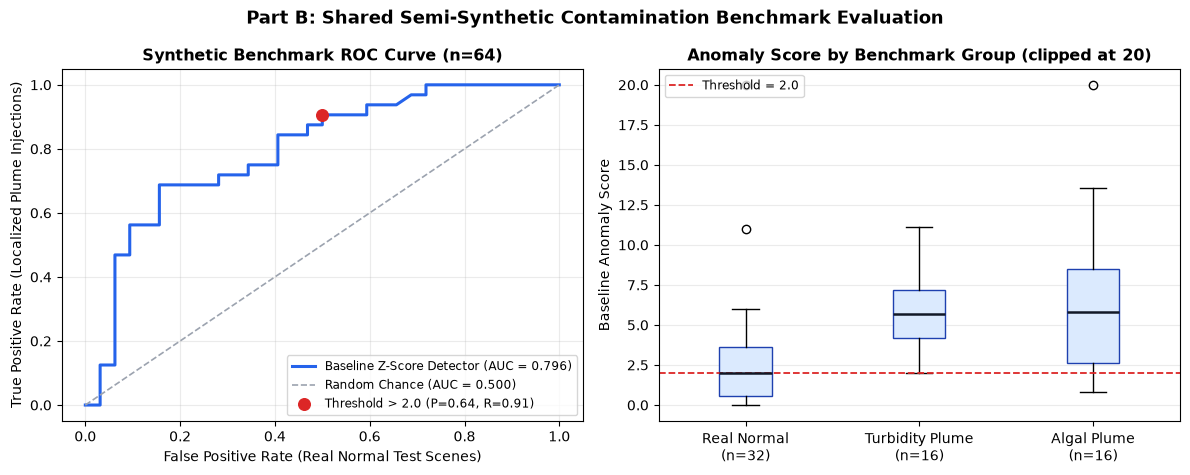

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\docs\figures\anomaly_benchmark_evaluation.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Panel 1: ROC curve
fpr, tpr, _ = roc_curve(y_true, y_score)
axes[0].plot(fpr, tpr, color="#2563eb", lw=2.2, label=f"Baseline Z-Score Detector (AUC = {roc_auc:.3f})")
axes[0].plot([0, 1], [0, 1], color="#9ca3af", linestyle="--", lw=1.2, label="Random Chance (AUC = 0.500)")
axes[0].scatter([fp / (fp + tn)], [tp / (tp + fn)], color="#dc2626", s=70, zorder=5, label=f"Threshold > 2.0 (P={prec:.2f}, R={rec:.2f})")
axes[0].set_title("Synthetic Benchmark ROC Curve (n=64)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("False Positive Rate (Real Normal Test Scenes)")
axes[0].set_ylabel("True Positive Rate (Localized Plume Injections)")
axes[0].legend(loc="lower right", fontsize=8.5)
axes[0].grid(alpha=0.25)

# Panel 2: Score distributions normal vs injected by scenario
norm_scores = benchmark_df.loc[benchmark_df["label"] == 0, "baseline_anomaly_score"]
turb_scores = benchmark_df.loc[benchmark_df["contamination_scenario"] == "turbidity_sediment", "baseline_anomaly_score"]
algal_scores = benchmark_df.loc[benchmark_df["contamination_scenario"] == "algal_bloom", "baseline_anomaly_score"]

axes[1].boxplot(
    [np.clip(norm_scores, 0, 20), np.clip(turb_scores, 0, 20), np.clip(algal_scores, 0, 20)],
    tick_labels=["Real Normal\n(n=32)", "Turbidity Plume\n(n=16)", "Algal Plume\n(n=16)"],
    patch_artist=True,
    boxprops=dict(facecolor="#dbeafe", color="#1e40af"),
    medianprops=dict(color="#111827", linewidth=1.8),
)
axes[1].axhline(ANOMALY_THRESHOLD, color="#dc2626", linestyle="--", lw=1.3, label="Threshold = 2.0")
axes[1].set_title("Anomaly Score by Benchmark Group (clipped at 20)", fontsize=11.5, fontweight="bold")
axes[1].set_ylabel("Baseline Anomaly Score")
axes[1].legend(loc="upper left", fontsize=8.5)
axes[1].grid(axis="y", alpha=0.25)

fig.suptitle("Part B: Shared Semi-Synthetic Contamination Benchmark Evaluation", fontsize=13, fontweight="bold")
fig.tight_layout()
bench_fig_path = FIG_DIR / "anomaly_benchmark_evaluation.png"
fig.savefig(bench_fig_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", bench_fig_path)

## 5. Part C (Step 6) — Spatial Pollution Hotspot Extraction & Polygon Validation

For every lake and real chronological date $t \ge 3$ (strictly excluding synthetic injected patches and future dates $> t$):
1. **Historical water-pixel baseline:** Compute trailing 5-date water-pixel `median` and `MAD` for `NDCI` and `NDTI` within `water_mask > 0.5`, guarded by a lake-specific historical stability floor $\epsilon = \max(0.02,\, 0.25 	imes 	ext{MAD}_{	ext{hist}})$ computed strictly over prior real dates $0\dots \min(t, 24)-1$.
2. **Pixel severity & clustering:** Mask pixels strictly inside `water_mask > 0.5`, calculate pixel-level positive robust Z-scores $z_{	ext{NDCI}}$ and $z_{	ext{NDTI}}$, normalize via $	ext{clip}(z / 6.0,\ 0,\ 1)$, flag pixels where $z_{	ext{NDCI}} > 2.0$ or $z_{	ext{NDTI}} > 2.0$, and run 8-connected clustering (`scipy.ndimage.label`).
3. **Noise removal & dominant signal:** Discard tiny connected components with `< 3` pixels. Classify `dominant_signal` strictly into `algal_bloom_proxy`, `turbidity_sediment_proxy`, or `combined`. Dates with zero valid clusters honestly return `[]`.
4. **Georeferencing & polygon validation:** Verified north-up orientation maps `(row, col)` pixel centers cleanly via `lon = min_lon + (col + 0.5) * (max_lon - min_lon) / 64` and `lat = max_lat - (row + 0.5) * (max_lat - min_lat) / 64` (`EPSG:4326`), verified against each lake's GeoJSON boundary polygon (`data/processed/lake_boundaries/*.geojson`).

In [7]:
def load_geojson_polygons(geojson_path: Path) -> list[tuple[MplPath, list[MplPath]]]:
    gj = json.loads(geojson_path.read_text(encoding="utf-8"))
    polys = []
    for feat in gj["features"]:
        geom = feat["geometry"]
        if geom["type"] == "Polygon":
            polys.append((MplPath(geom["coordinates"][0]), [MplPath(h) for h in geom["coordinates"][1:]]))
        elif geom["type"] == "MultiPolygon":
            for poly in geom["coordinates"]:
                polys.append((MplPath(poly[0]), [MplPath(h) for h in poly[1:]]))
    return polys

def point_in_polygons(lon: float, lat: float, polys: list[tuple[MplPath, list[MplPath]]]) -> bool:
    for ext, holes in polys:
        if ext.contains_point((lon, lat)):
            if not any(h.contains_point((lon, lat)) for h in holes):
                return True
    return False

def pixel_to_wgs84(row: float, col: float, bounds: list[float], height: int = 64, width: int = 64) -> tuple[float, float]:
    """Convert north-up pixel coordinates (with +0.5 pixel-center offset) to EPSG:4326 (lon, lat)."""
    min_lon, min_lat, max_lon, max_lat = bounds
    lon = min_lon + (col + 0.5) * ((max_lon - min_lon) / float(width))
    lat = max_lat - (row + 0.5) * ((max_lat - min_lat) / float(height))
    return float(lon), float(lat)

# Verify north-up grid orientation per lake (union of valid water pixels inside GeoJSON >= 95%)
orientation_rows = []
lake_polys = {}
for lake in OFFICIAL_LAKES:
    polys = load_geojson_polygons(BOUNDARY_DIR / f"{lake}.geojson")
    lake_polys[lake] = polys
    npz = np.load(PATCH_DIR / f"{lake}.npz", allow_pickle=False)
    patches = npz["patches"]
    ch = [str(c) for c in npz["channel_names"]]
    bounds = [float(b) for b in npz["bounds"]]
    union_mask = (patches[:, ch.index("water_mask")] > 0.5).any(axis=0)
    rs, cs = np.where(union_mask)
    nu_in = np.mean([point_in_polygons(*pixel_to_wgs84(r, c, bounds), polys) for r, c in zip(rs, cs)])
    fl_in = np.mean([point_in_polygons(*pixel_to_wgs84(63 - r, c, bounds), polys) for r, c in zip(rs, cs)])
    orientation_rows.append({
        "lake_id": lake,
        "north_up_inside_pct": round(100.0 * nu_in, 2),
        "flipped_inside_pct": round(100.0 * fl_in, 2),
        "orientation_verified": bool(nu_in > fl_in and nu_in > 0.95),
    })
    assert nu_in > fl_in and nu_in > 0.95, f"{lake} failed north-up verification"
display(pd.DataFrame(orientation_rows))

# Extract spatial hotspots across all 4 lakes and real dates
spatial_hotspots = {}
hotspot_stats = []
ALLOWED_SIGNALS = {"algal_bloom_proxy", "turbidity_sediment_proxy", "combined"}

for lake in OFFICIAL_LAKES:
    npz = np.load(PATCH_DIR / f"{lake}.npz", allow_pickle=False)
    patches = npz["patches"]
    ch = [str(c) for c in npz["channel_names"]]
    bounds = [float(b) for b in npz["bounds"]]
    dates = [str(d) for d in npz["dates"]]
    polys = lake_polys[lake]

    i_ndci = ch.index("NDCI")
    i_ndti = ch.index("NDTI")
    i_mask = ch.index("water_mask")

    spatial_hotspots[lake] = {}
    lake_total_clusters = 0
    lake_outside_clusters = 0
    dates_with_clusters = 0

    for t, date_str in enumerate(dates):
        if t < MIN_HISTORY:
            spatial_hotspots[lake][date_str] = []
            continue

        # Causal historical water-pixel windows (no future dates, no injected data)
        win_ndci = np.concatenate([patches[k, i_ndci][patches[k, i_mask] > 0.5] for k in range(max(0, t - TRAILING_WINDOW), t)])
        win_ndti = np.concatenate([patches[k, i_ndti][patches[k, i_mask] > 0.5] for k in range(max(0, t - TRAILING_WINDOW), t)])
        ref_ndci = np.concatenate([patches[k, i_ndci][patches[k, i_mask] > 0.5] for k in range(0, min(t, TRAIN_REF_DATES))])
        ref_ndti = np.concatenate([patches[k, i_ndti][patches[k, i_mask] > 0.5] for k in range(0, min(t, TRAIN_REF_DATES))])

        win_ndci = win_ndci[np.isfinite(win_ndci)]
        win_ndti = win_ndti[np.isfinite(win_ndti)]
        ref_ndci = ref_ndci[np.isfinite(ref_ndci)]
        ref_ndti = ref_ndti[np.isfinite(ref_ndti)]

        med_c = float(np.median(win_ndci))
        mad_c = float(np.median(np.abs(win_ndci - med_c)))
        eps_c = max(0.02, 0.25 * float(np.median(np.abs(ref_ndci - np.median(ref_ndci)))))

        med_t = float(np.median(win_ndti))
        mad_t = float(np.median(np.abs(win_ndti - med_t)))
        eps_t = max(0.02, 0.25 * float(np.median(np.abs(ref_ndti - np.median(ref_ndti)))))

        wmask = (patches[t, i_mask] > 0.5) & np.isfinite(patches[t, i_ndci]) & np.isfinite(patches[t, i_ndti])
        z_c = np.where(wmask, np.maximum(0.0, 0.6745 * (patches[t, i_ndci] - med_c) / max(mad_c, eps_c)), 0.0)
        z_t = np.where(wmask, np.maximum(0.0, 0.6745 * (patches[t, i_ndti] - med_t) / max(mad_t, eps_t)), 0.0)

        norm_c = np.clip(z_c / 6.0, 0.0, 1.0)
        norm_t = np.clip(z_t / 6.0, 0.0, 1.0)
        sev_map = np.maximum(norm_c, norm_t)
        flagged_px = wmask & ((z_c > ANOMALY_THRESHOLD) | (z_t > ANOMALY_THRESHOLD))

        labeled, n_comp = ndimage.label(flagged_px, structure=np.ones((3, 3), dtype=int))
        clusters = []
        for cid in range(1, n_comp + 1):
            cmask = labeled == cid
            px_count = int(cmask.sum())
            if px_count < 3:
                continue

            rows, cols = np.where(cmask)
            w_vals = np.maximum(sev_map[cmask], 1e-6)
            cr = float(np.average(rows, weights=w_vals))
            cc = float(np.average(cols, weights=w_vals))
            lon, lat = pixel_to_wgs84(cr, cc, bounds)

            if not point_in_polygons(lon, lat, polys):
                cr_u, cc_u = float(np.mean(rows)), float(np.mean(cols))
                lon_u, lat_u = pixel_to_wgs84(cr_u, cc_u, bounds)
                if point_in_polygons(lon_u, lat_u, polys):
                    lon, lat = lon_u, lat_u
                else:
                    # Fallback to closest cluster pixel inside polygon
                    valid_pts = [(r, c, pixel_to_wgs84(r, c, bounds)) for r, c in zip(rows, cols)]
                    inside_pts = [(r, c, pt) for r, c, pt in valid_pts if point_in_polygons(pt[0], pt[1], polys)]
                    if inside_pts:
                        best = min(inside_pts, key=lambda item: (item[0] - cr) ** 2 + (item[1] - cc) ** 2)
                        lon, lat = best[2]

            inside_ok = point_in_polygons(lon, lat, polys)
            if not inside_ok:
                lake_outside_clusters += 1

            zc_mean = float(np.mean(z_c[cmask]))
            zt_mean = float(np.mean(z_t[cmask]))
            zc_max = float(np.max(z_c[cmask]))
            zt_max = float(np.max(z_t[cmask]))
            if (zc_max > ANOMALY_THRESHOLD and zt_max > ANOMALY_THRESHOLD) and (min(zc_mean, zt_mean) >= 0.5 * max(zc_mean, zt_mean)):
                dom_sig = "combined"
            elif zc_mean >= zt_mean:
                dom_sig = "algal_bloom_proxy"
            else:
                dom_sig = "turbidity_sediment_proxy"
            assert dom_sig in ALLOWED_SIGNALS

            clusters.append({
                "lat": round(lat, 6),
                "lon": round(lon, 6),
                "pixel_count": px_count,
                "peak_ndci": round(float(np.max(patches[t, i_ndci][cmask])), 5),
                "peak_ndti": round(float(np.max(patches[t, i_ndti][cmask])), 5),
                "dominant_signal": dom_sig,
                "severity_score": round(float(0.5 * np.mean(sev_map[cmask]) + 0.5 * np.max(sev_map[cmask])), 4),
            })

        # Sort descending by severity_score and assign deterministic hotspot_id
        clusters.sort(key=lambda c: (-c["severity_score"], -c["pixel_count"]))
        final_clusters = []
        for rank, c in enumerate(clusters, start=1):
            final_clusters.append({
                "hotspot_id": f"{lake}_{date_str}_h{rank:02d}",
                **c,
            })

        spatial_hotspots[lake][date_str] = final_clusters
        lake_total_clusters += len(final_clusters)
        if final_clusters:
            dates_with_clusters += 1

    hotspot_stats.append({
        "lake_id": lake,
        "dates_processed": len(dates),
        "dates_with_hotspots": dates_with_clusters,
        "total_hotspots": lake_total_clusters,
        "outside_polygon_count": lake_outside_clusters,
        "latest_date": dates[-1],
        "latest_date_hotspots": len(spatial_hotspots[lake][dates[-1]]),
    })

hotspots_path = DATA_DIR / "spatial_hotspots.json"
with open(hotspots_path, "w", encoding="utf-8") as f:
    json.dump(spatial_hotspots, f, indent=2)

print(f"Saved {hotspots_path}")
display(pd.DataFrame(hotspot_stats))

,lake_id,north_up_inside_pct,flipped_inside_pct,orientation_verified
0,bellandur,100.00,52.66,True
1,hussain_sagar,99.05,74.55,True
2,yamuna_okhla,97.37,28.33,True
3,sukhna,98.95,46.05,True


Saved C:\Users\somya\OneDrive\Desktop\miniproject\data\processed\spatial_hotspots.json


,lake_id,dates_processed,dates_with_hotspots,total_hotspots,outside_polygon_count,latest_date,latest_date_hotspots
0,bellandur,32,19,41,0,2026-11-23,3
1,hussain_sagar,32,18,33,0,2026-11-18,0
2,yamuna_okhla,32,19,64,0,2026-11-24,1
3,sukhna,32,14,32,0,2026-11-24,0


### Visual Verification Overlay (`docs/figures/hotspots_verification.png`)

Plot all four GeoJSON boundaries in WGS84 (`EPSG:4326`) together with extracted hotspot markers from the latest observation date having at least one valid hotspot per lake (honestly annotating when the terminal observation date had zero valid clusters).

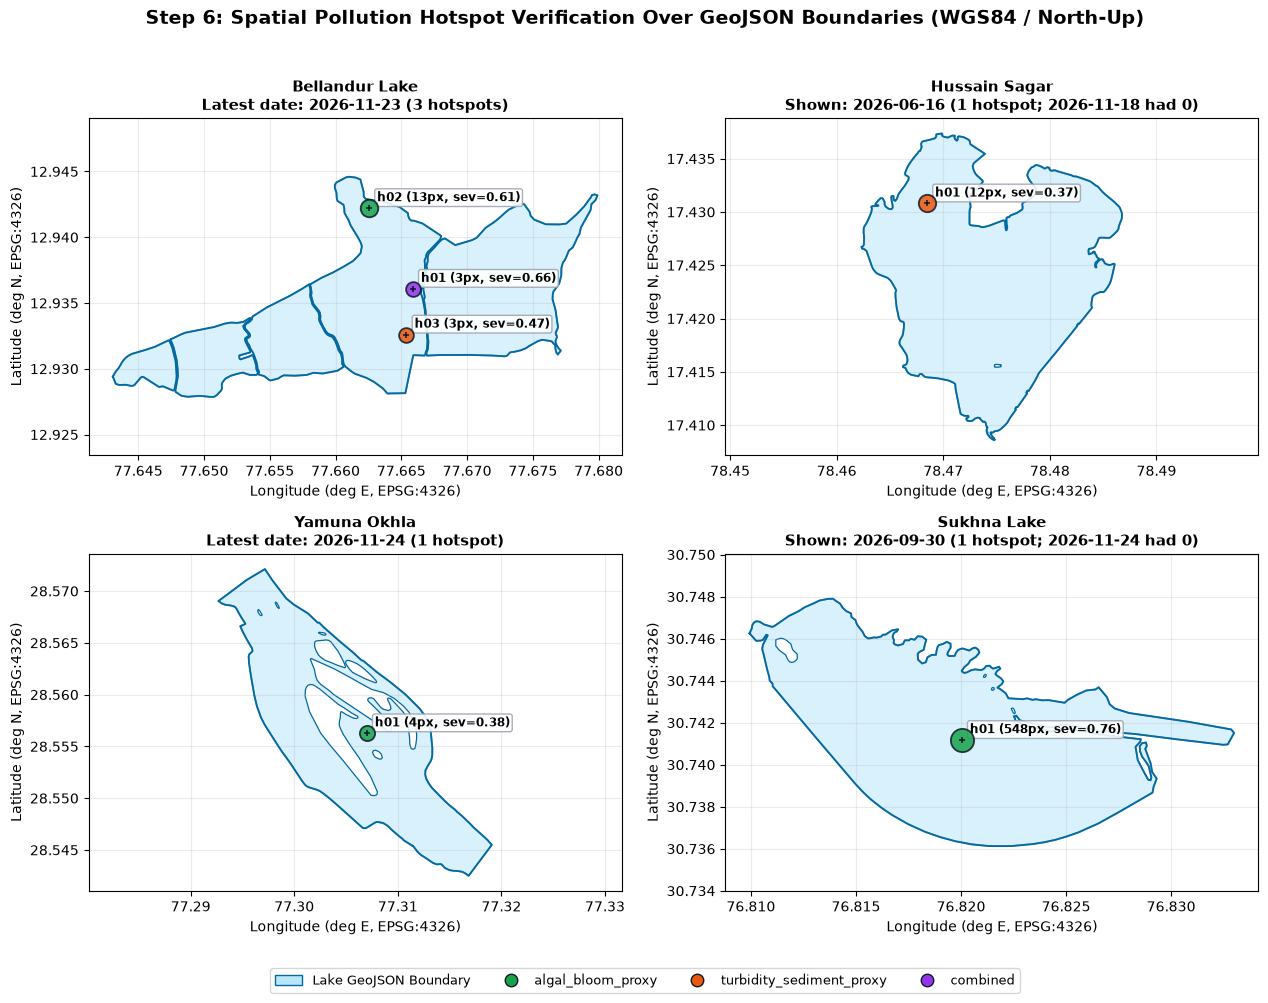

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\docs\figures\hotspots_verification.png


In [8]:
SIGNAL_COLORS = {
    "algal_bloom_proxy": "#16a34a",
    "turbidity_sediment_proxy": "#ea580c",
    "combined": "#9333ea",
}

def plot_geojson_boundary(ax, geojson_path: Path):
    gj = json.loads(geojson_path.read_text(encoding="utf-8"))
    for feat in gj["features"]:
        geom = feat["geometry"]
        polys = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
        for poly in polys:
            ext = np.array(poly[0])
            ax.fill(ext[:, 0], ext[:, 1], facecolor="#bae6fd", edgecolor="#0369a1", linewidth=1.3, alpha=0.55)
            ax.plot(ext[:, 0], ext[:, 1], color="#0369a1", linewidth=1.3)
            for hole in poly[1:]:
                h_arr = np.array(hole)
                ax.fill(h_arr[:, 0], h_arr[:, 1], facecolor="white", edgecolor="#0369a1", linewidth=0.9)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, lake in zip(axes.flat, OFFICIAL_LAKES):
    plot_geojson_boundary(ax, BOUNDARY_DIR / f"{lake}.geojson")
    dates = sorted(spatial_hotspots[lake].keys())
    dates_nonempty = [d for d in dates if len(spatial_hotspots[lake][d]) > 0]
    chosen_date = dates_nonempty[-1]
    latest_date = dates[-1]
    hs_list = spatial_hotspots[lake][chosen_date]

    for hs in hs_list:
        col = SIGNAL_COLORS[hs["dominant_signal"]]
        size = float(np.clip(70 + 25 * np.sqrt(hs["pixel_count"]), 80, 280))
        ax.scatter(hs["lon"], hs["lat"], s=size, color=col, edgecolor="#111827", linewidth=1.3, zorder=6, alpha=0.85)
        ax.scatter(hs["lon"], hs["lat"], s=18, color="#111827", marker="+", linewidth=1.1, zorder=7)
        ax.annotate(
            f"{hs['hotspot_id'].split('_')[-1]} ({hs['pixel_count']}px, sev={hs['severity_score']:.2f})",
            xy=(hs["lon"], hs["lat"]),
            xytext=(6, 5),
            textcoords="offset points",
            fontsize=8.5,
            fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="#9ca3af", alpha=0.88),
        )

    subtitle = (
        f"Latest date: {chosen_date} ({len(hs_list)} hotspot{'s' if len(hs_list) != 1 else ''})"
        if chosen_date == latest_date
        else f"Shown: {chosen_date} ({len(hs_list)} hotspot; {latest_date} had 0)"
    )
    ax.set_title(f"{LAKE_DISPLAY_NAMES[lake]}\n{subtitle}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Longitude (deg E, EPSG:4326)")
    ax.set_ylabel("Latitude (deg N, EPSG:4326)")
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(alpha=0.25)

legend_handles = [
    MplPatch(facecolor="#bae6fd", edgecolor="#0369a1", label="Lake GeoJSON Boundary"),
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=SIGNAL_COLORS["algal_bloom_proxy"], markeredgecolor="#111827", markersize=9, label="algal_bloom_proxy"),
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=SIGNAL_COLORS["turbidity_sediment_proxy"], markeredgecolor="#111827", markersize=9, label="turbidity_sediment_proxy"),
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=SIGNAL_COLORS["combined"], markeredgecolor="#111827", markersize=9, label="combined"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=4, fontsize=9.5, frameon=True, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Step 6: Spatial Pollution Hotspot Verification Over GeoJSON Boundaries (WGS84 / North-Up)", fontsize=13.5, fontweight="bold")
fig.tight_layout(rect=[0, 0.04, 1, 0.96])

hs_fig_path = FIG_DIR / "hotspots_verification.png"
fig.savefig(hs_fig_path, dpi=170, bbox_inches="tight")
plt.show()
print("Saved:", hs_fig_path)

## 6. Part D — Automated Integrity & Schema Validation

Re-open every saved artifact from disk and programmatically verify all Step 5, Part B, and Step 6 contracts.

In [9]:
# 1. Validate sentinel_anomalies.csv
re_anom = pd.read_csv(DATA_DIR / "sentinel_anomalies.csv")
assert len(re_anom) == 128
assert sorted(re_anom["lake_id"].unique().tolist()) == sorted(OFFICIAL_LAKES)
for col in ANOMALY_INDICATORS:
    zcol = f"z_pos_{col}"
    assert zcol in re_anom.columns
    assert (re_anom.loc[re_anom["sufficient_history"], zcol] >= 0).all()
assert (re_anom.loc[~re_anom["sufficient_history"], "is_anomaly"] == False).all()
assert (re_anom.loc[re_anom["sufficient_history"], "is_anomaly"] == (re_anom.loc[re_anom["sufficient_history"], "baseline_anomaly_score"] > 2.0)).all()

# Confirm sentinel_timeseries.csv remained unaltered (exact 36 columns, 128 rows)
re_raw = pd.read_csv(DATA_DIR / "sentinel_timeseries.csv")
assert re_raw.shape == (128, 36)

# 2. Validate anomaly_benchmark.csv & anomaly_benchmark.npz alignment
re_bench_csv = pd.read_csv(DATA_DIR / "anomaly_benchmark.csv")
re_bench_npz = np.load(DATA_DIR / "anomaly_benchmark.npz", allow_pickle=False)
assert len(re_bench_csv) == 64
assert re_bench_npz["patches"].shape == (64, 9, 64, 64)
assert np.array_equal(re_bench_csv["case_id"].to_numpy(dtype=str), re_bench_npz["case_ids"])
assert np.array_equal(re_bench_csv["label"].to_numpy(dtype=np.int64), re_bench_npz["labels"])
assert int((re_bench_csv["label"] == 0).sum()) == 32
assert int((re_bench_csv["label"] == 1).sum()) == 32
assert ((re_bench_csv.loc[re_bench_csv["label"] == 1, "injection_pct"] >= 10.0) & (re_bench_csv.loc[re_bench_csv["label"] == 1, "injection_pct"] <= 25.0)).all()

# 3. Validate baseline_metrics.json preserves regression metrics AND adds anomaly_benchmark
re_metrics = json.loads((MODELS_DIR / "baseline_metrics.json").read_text(encoding="utf-8"))
assert "selected_models" in re_metrics and "Chla" in re_metrics["selected_models"] and "TSS" in re_metrics["selected_models"]
assert "anomaly_benchmark" in re_metrics and re_metrics["anomaly_benchmark"]["benchmark_size"] == 64

# 4. Validate spatial_hotspots.json schema & polygon containment
re_hs = json.loads((DATA_DIR / "spatial_hotspots.json").read_text(encoding="utf-8"))
assert sorted(re_hs.keys()) == sorted(OFFICIAL_LAKES)
req_hs_fields = {"hotspot_id", "lat", "lon", "pixel_count", "peak_ndci", "peak_ndti", "dominant_signal", "severity_score"}
total_hs_checked = 0
for lake, by_date in re_hs.items():
    assert len(by_date) == 32
    polys = lake_polys[lake]
    for date_str, items in by_date.items():
        pd.to_datetime(date_str)
        for item in items:
            assert set(item.keys()) == req_hs_fields
            assert np.isfinite(item["lat"]) and np.isfinite(item["lon"])
            assert np.isfinite(item["severity_score"]) and np.isfinite(item["peak_ndci"]) and np.isfinite(item["peak_ndti"])
            assert isinstance(item["pixel_count"], int) and item["pixel_count"] >= 3
            assert item["dominant_signal"] in ALLOWED_SIGNALS
            assert point_in_polygons(item["lon"], item["lat"], polys), f"Outside polygon: {item}"
            total_hs_checked += 1

print(f"ALL VALIDATION CHECKS PASSED: 128 anomaly rows, 64 benchmark CSV+NPZ cases, baseline_metrics.json intact, and {total_hs_checked}/{total_hs_checked} hotspots inside GeoJSON boundaries.")

ALL VALIDATION CHECKS PASSED: 128 anomaly rows, 64 benchmark CSV+NPZ cases, baseline_metrics.json intact, and 170/170 hotspots inside GeoJSON boundaries.
